# Makkah Retail Sales — 02: Data-Quality Review

This notebook **finds** problems; it does not fix them. Each check in `dq/checks.py` returns a list of issues, ranked by severity, with the evidence and a suggested action.

The output is a review queue for a person:

| File | Who writes it | What it holds |
|---|---|---|
| `data/review/issues.csv` | this notebook | every issue found |
| `data/review/decisions.csv` | **a person** | `approve`, `reject` or `edit` for each issue, plus a note |

`03_apply_decisions.ipynb` then applies only what the person approved.

The checks are written as plain functions so they can later be run by an automated agent on new data.

In [1]:
from pathlib import Path
import pandas as pd
from dq import checks

INTERIM, REVIEW = Path("data/interim"), Path("data/review")
REVIEW.mkdir(parents=True, exist_ok=True)

cities = pd.read_csv(INTERIM / "cities_weekly.csv", parse_dates=["starting_date"])
sectors = pd.read_csv(INTERIM / "sectors_weekly.csv", parse_dates=["starting_date"])
national = pd.read_csv(INTERIM / "national_weekly.csv", parse_dates=["starting_date"]).set_index("starting_date")
published = pd.read_csv(INTERIM / "published_changes.csv", parse_dates=["starting_date"])

cal = checks.calendar_flags(pd.concat([cities.starting_date, sectors.starting_date]))
cities = cities.merge(cal, on="starting_date", how="left")
sectors = sectors.merge(cal, on="starting_date", how="left").assign(covid_period=lambda d: d.starting_date < "2020-06-21")
issues = []

## Check 1 — Missing values and duplicates

In [2]:
issues += checks.check_missing_and_duplicates(cities, "cities", ["starting_date", "city"])
issues += checks.check_missing_and_duplicates(sectors, "sectors", ["starting_date", "sectors"])
len(issues)

0

## Check 2 — Week regularity (every week starts on Sunday, 7 days apart)

In [3]:
for city, g in cities.query("city == 'Makkah'").groupby("city"):
    issues += checks.check_week_regularity(g, "cities (Makkah)")
issues += checks.check_week_regularity(sectors, "sectors")
[i for i in issues if i["check"] in ("week_start_day", "missing_weeks")]

[{'check': 'missing_weeks',
  'table': 'cities (Makkah)',
  'key': '2025-08-24',
  'detail': '6 week(s) missing before this date',
  'evidence': 'gap of 49 days',
  'severity': 'medium',
  'suggestion': 'Look for the missing reports; otherwise document the gap'},
 {'check': 'missing_weeks',
  'table': 'cities (Makkah)',
  'key': '2026-02-08',
  'detail': '20 week(s) missing before this date',
  'evidence': 'gap of 147 days',
  'severity': 'medium',
  'suggestion': 'Look for the missing reports; otherwise document the gap'},
 {'check': 'missing_weeks',
  'table': 'cities (Makkah)',
  'key': '2026-08-02',
  'detail': '21 week(s) missing before this date',
  'evidence': 'gap of 154 days',
  'severity': 'medium',
  'suggestion': 'Look for the missing reports; otherwise document the gap'}]

## Check 3 — Parts add up to the total (CSV source)

In [4]:
csv_cities = cities.query("source == 'kapsarc_csv'")
issues += checks.check_parts_sum_to_total(csv_cities, national, "cities", "starting_date", "sales_m_sar")
issues += checks.check_parts_sum_to_total(sectors, national, "sectors", "starting_date", "sales_m_sar")

## Check 4 — City names across the two sources

The CSV and the PDFs spell some cities differently. The check lists every CSV city with no exact match in the PDFs and the closest names.
A person must confirm each pair is the **same place with the same definition** — for example `Other` (CSV: everything outside 10 cities) and `Others` (PDF: everything outside ~60 cities) look alike but mean different things.

In [5]:
name_issues = checks.check_name_consistency(
    cities.query("source == 'kapsarc_csv'").city.unique(),
    cities.query("source == 'sama_pdf'").city.unique(),
    "CSV", "PDF", "cities")
issues += name_issues
pd.DataFrame(name_issues)[["key", "evidence", "suggestion"]]

,key,evidence,suggestion
0,Hail,"closest: ['Hayel', 'Al-Khafji', 'Al-Jubail']",Map 'Hail' → 'Hayel' if they are the same plac...
1,Khobar,"closest: ['Al-Khubar', 'Al-Kharj']",Map 'Khobar' → 'Al-Khubar' if they are the sam...
2,Madina,closest: ['Al-Madinah'],Map 'Madina' → 'Al-Madinah' if they are the sa...
3,Other,closest: ['Others'],Map 'Other' → 'Others' if they are the same pl...


## Check 5 — Unusual weeks (outliers)

Each week is compared with the median of its neighbouring weeks. Weeks far from it are flagged, then tagged with known events (Ramadan, Eid, Hajj, COVID curfew).
Flagged weeks **with** a known event are listed as `low` (probably real); weeks **without** one are `medium`/`high` and need a person to check the source.

In [6]:
issues += checks.check_outliers(cities, "cities", "city", "sales_m_sar")
issues += checks.check_outliers(sectors, "sectors", "sectors", "sales_m_sar")
out = pd.DataFrame([i for i in issues if i["check"] == "outlier"])
out.groupby(["table", "severity"]).size().unstack(fill_value=0)

severity,low,medium
table,,
cities,58,1
sectors,140,6


## Check 6 — Published % changes match the values (CSV source)

In [7]:
pub_city = (published.query("sectors == 'Total' and city != 'Total'")
            .assign(city=lambda d: d.city.str.title())[["starting_date", "city", "value"]]
            .rename(columns={"value": "published_change"}))
chg_issues, n_compared, n_bad = checks.check_published_change(
    csv_cities, pub_city, "cities", "city", "sales_m_sar", "published_change")
issues += chg_issues
print(f"Compared {n_compared} weeks → {n_bad} mismatches")

Compared 2959 weeks → 0 mismatches


## Review queue

In [8]:
report = checks.to_report(issues)
report.to_csv(REVIEW / "issues.csv", index=False)

summary = report.pivot_table(index="check", columns="severity", values="issue_id", aggfunc="count", fill_value=0)
summary = summary.reindex(columns=[c for c in ["high", "medium", "low"] if c in summary.columns])
summary

severity,medium,low
check,,
missing_weeks,3,0
name_mismatch,4,0
outlier,7,198


In [9]:
# Issues that need a person first: everything that is not 'low'
report.query("severity != 'low'")[["issue_id", "severity", "check", "key", "detail", "evidence", "suggestion"]]

,issue_id,severity,check,key,detail,evidence,suggestion
0,DQ-40d91f9d,medium,missing_weeks,2025-08-24,6 week(s) missing before this date,gap of 49 days,Look for the missing reports; otherwise docume...
1,DQ-1e483a14,medium,missing_weeks,2026-02-08,20 week(s) missing before this date,gap of 147 days,Look for the missing reports; otherwise docume...
2,DQ-94ac09f0,medium,missing_weeks,2026-08-02,21 week(s) missing before this date,gap of 154 days,Look for the missing reports; otherwise docume...
3,DQ-8d541356,medium,name_mismatch,Hail,'Hail' (CSV) has no exact match in PDF,"closest: ['Hayel', 'Al-Khafji', 'Al-Jubail']",Map 'Hail' → 'Hayel' if they are the same plac...
4,DQ-bf03bac7,medium,name_mismatch,Khobar,'Khobar' (CSV) has no exact match in PDF,"closest: ['Al-Khubar', 'Al-Kharj']",Map 'Khobar' → 'Al-Khubar' if they are the sam...
5,DQ-30aca21d,medium,name_mismatch,Madina,'Madina' (CSV) has no exact match in PDF,closest: ['Al-Madinah'],Map 'Madina' → 'Al-Madinah' if they are the sa...
6,DQ-3c32d348,medium,name_mismatch,Other,'Other' (CSV) has no exact match in PDF,closest: ['Others'],Map 'Other' → 'Others' if they are the same pl...
7,DQ-c2b23fda,medium,outlier,Electronic & Electric Devices | 2022-05-29,Above its neighbouring weeks by 69% — no known...,"value=413.3, z=4.9",Check the source report for this week
8,DQ-ea9165f4,medium,outlier,Electronic & Electric Devices | 2023-05-28,Above its neighbouring weeks by 47% — no known...,"value=380.9, z=3.6",Check the source report for this week
9,DQ-0a1614d8,medium,outlier,Hotels | 2021-01-03,Above its neighbouring weeks by 79% — no known...,"value=276.7, z=5.1",Check the source report for this week


## How to review an issue

Look at the data before deciding. `plot_issue` draws the weeks around a flagged week, the median it was compared with, and the flagged week in red.

Questions to ask:
- Is there an event that week the checks don't know about (a holiday, a sale, a policy change)?
- Do other cities or sectors move the same way that week? If yes, it is probably real.
- Is the jump a round multiple (×10, ×1000) or a sudden one-week spike with nothing around it? That points to a typing or unit error.

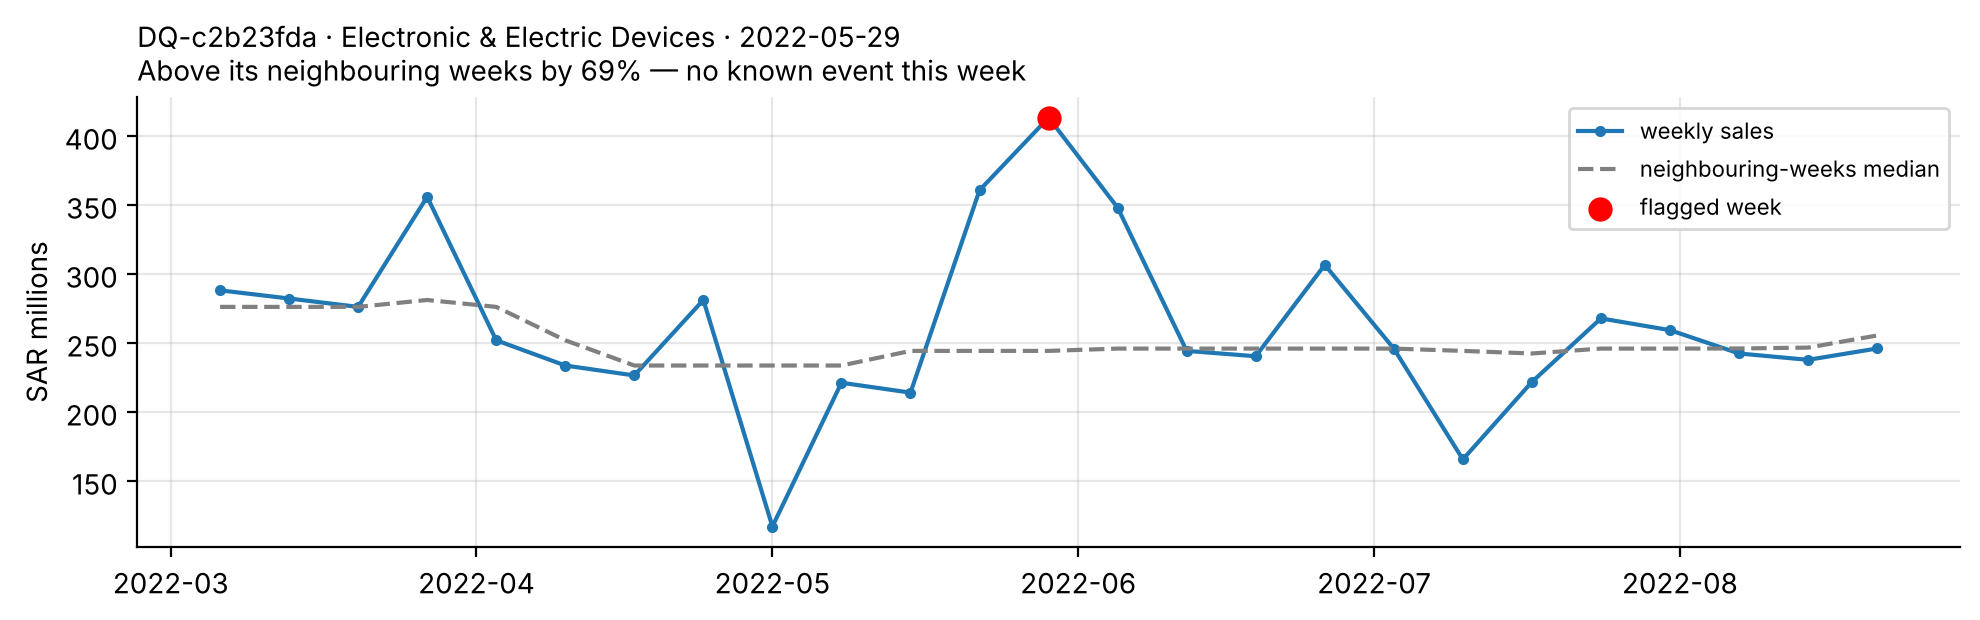

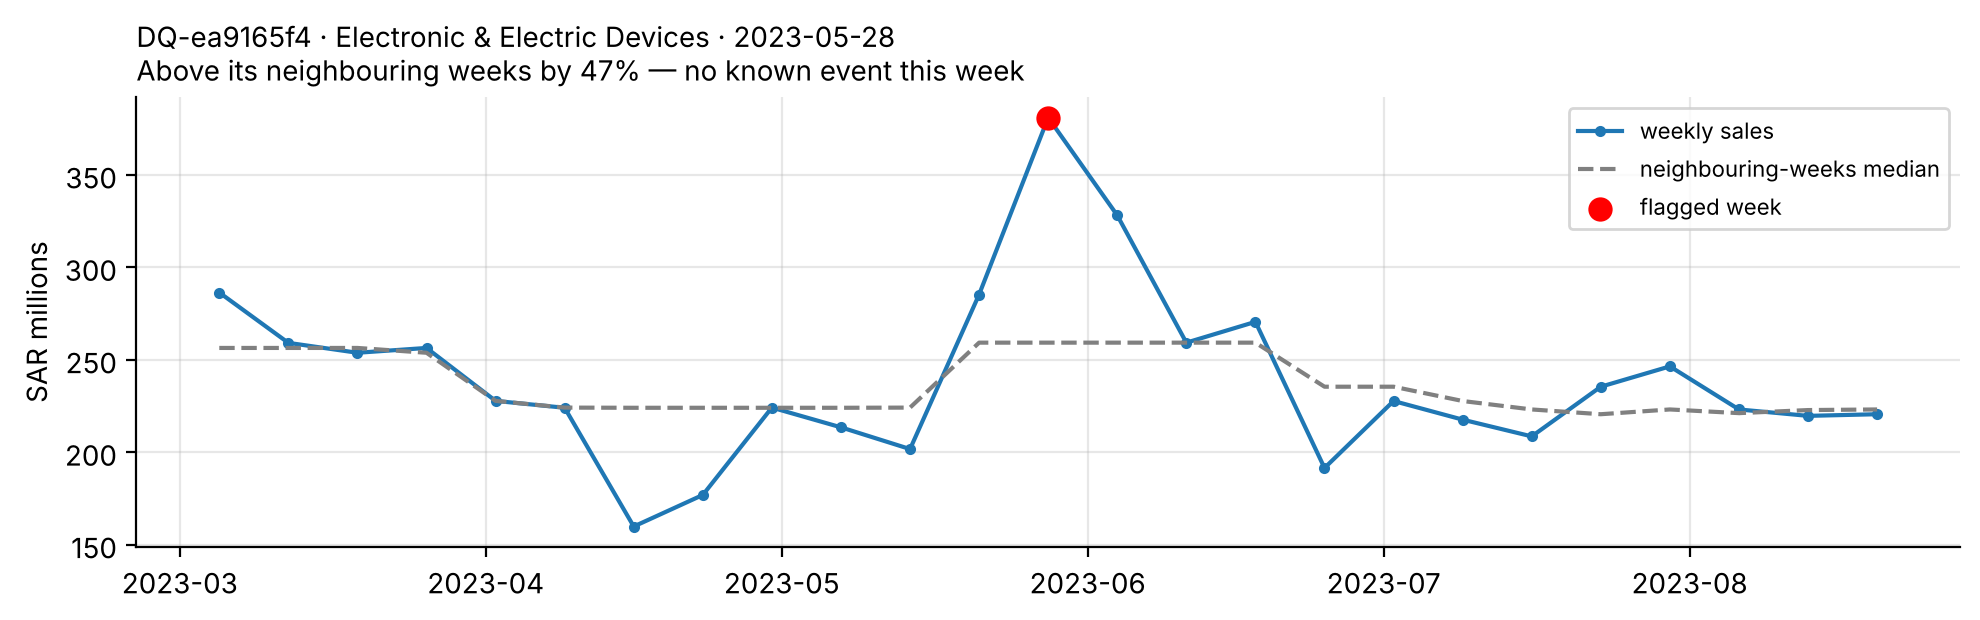

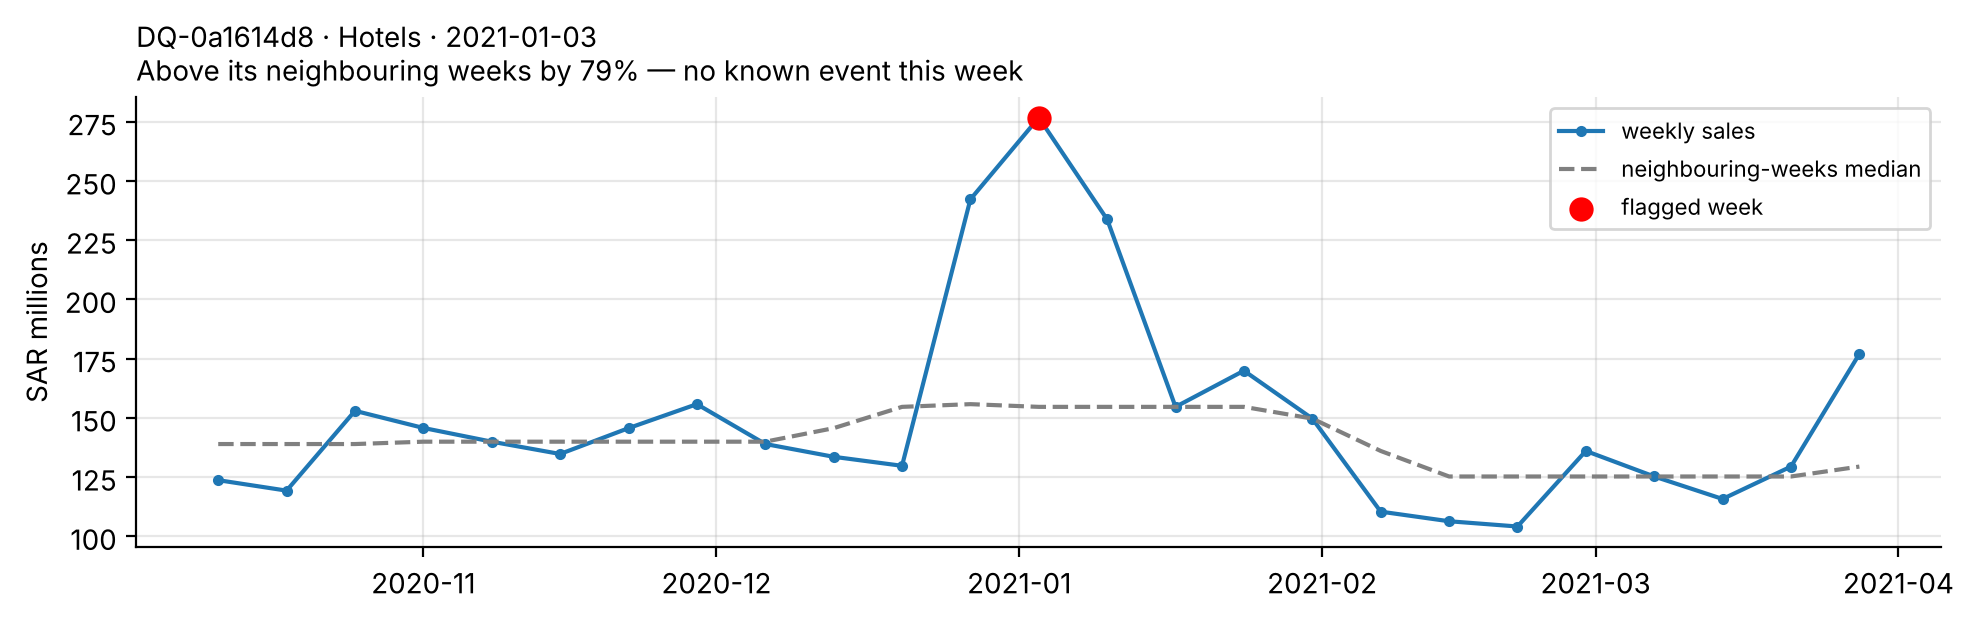

In [10]:
pending = report.query("severity != 'low'")
for _, issue in pending.query("check == 'outlier'").head(3).iterrows():
    checks.plot_issue(issue, cities, sectors)

In [11]:
# Review any issue by its id, e.g. show("DQ-0a1614d8")
def show(issue_id):
    checks.plot_issue(report.loc[report.issue_id == issue_id].iloc[0], cities, sectors)

# Example — every city that jumped in the week of 27 Sep 2026, side by side:
week = "2026-09-27"
same_week = report[report.key.str.endswith(week)]
same_week[["issue_id", "key", "detail"]]

,issue_id,key,detail
17,DQ-a45de5a0,Ahad-Almasarha | 2026-09-27,Above its neighbouring weeks by 61% — during s...
19,DQ-17362a1b,Al-Badaea | 2026-09-27,Above its neighbouring weeks by 29% — during s...
20,DQ-898427b0,Al-Majma'a | 2026-09-27,Above its neighbouring weeks by 24% — during s...
21,DQ-15da51e4,Al-Rass | 2026-09-27,Above its neighbouring weeks by 33% — during s...
153,DQ-458dbb6b,Mahayel | 2026-09-27,Above its neighbouring weeks by 43% — during s...
170,DQ-f327f6f4,Others | 2026-09-27,Above its neighbouring weeks by 29% — during s...
176,DQ-da256548,Rafha | 2026-09-27,Above its neighbouring weeks by 44% — during s...
194,DQ-f09f3e98,Sabya | 2026-09-27,Above its neighbouring weeks by 45% — during s...


## Decisions template

One row per issue. The reviewer fills `decision` using these words:

| Check | Allowed decisions |
|---|---|
| `name_mismatch` | `map` (use the name in `value`) or `separate` (different places) |
| `outlier` | `keep` (real) or `exclude` (flag the week so analysis skips it — nothing is deleted) |
| `missing_weeks` | `document` (no data to add) |

To save time, `low` outliers are pre-filled `keep` and missing weeks `document`; name issues get the closest name pre-filled in `value` but the decision is left to the reviewer.

In [12]:
dec_path = REVIEW / "decisions.csv"
def prefill(r):
    if r["check"] == "outlier" and r["severity"] == "low":
        return "keep"
    if r["check"] == "missing_weeks":
        return "document"
    return ""

template = report[["issue_id", "check", "key", "severity", "detail", "suggestion"]].copy()
template["decision"] = template.apply(prefill, axis=1)
template["value"] = [ev.split("'")[1] if c == "name_mismatch" and "'" in ev else ""
                     for c, ev in zip(report["check"], report["evidence"])]
template["note"], template["reviewer"] = "", ""
if dec_path.exists():  # keep decisions already made; add new issues only
    old = pd.read_csv(dec_path, dtype=str).fillna("")
    template = pd.concat([old, template[~template.issue_id.isin(old.issue_id)]], ignore_index=True)
template.to_csv(dec_path, index=False)
print(f"{(template.decision == '').sum()} issues waiting for a decision → {dec_path}")

0 issues waiting for a decision → data/review/decisions.csv
